# STEBBS paper: Figures 10-15

Compare SUEWS-STEBBS and EnergyPlus simulations with indoor observations for
Bristol, 2025. Run the notebook from top to bottom. Inputs are the deposited
modelling folders and the included indoor evaluation-period sample. Figures
are saved at 400 dpi in `figures/`; source data are not modified. The full
indoor observation record and outdoor AWS observations are not required.

## Setup

Modelling results for SUEWS-STEBBS and EnergyPlus will be available from
[Zenodo: 10.5281/zenodo.23955440](https://doi.org/10.5281/zenodo.23955440).
After downloading and extracting the deposit, replace `MODEL_DATA` with the
parent folder containing `SUEWS_STEBBS_modelling/` and `EnergyPlus_modelling/`.
This path is a placeholder, not a download location.

Indoor observations are read only from the included `sample_indoor_observation/`
folder. No model installation or simulation rerun is needed.

In [1]:
from pathlib import Path
from datetime import timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, Normalize, TwoSlopeNorm
from matplotlib.ticker import MultipleLocator

MODEL_DATA = Path('path/to/extracted_modelling_data')
INDOOR_OBSERVATION_FILE = Path(
    'sample_indoor_observation/BRTYND_indoor_temperature_sample.csv.csv'
)
FIGURE_DIR = Path('figures')
FIGURE_DIR.mkdir(exist_ok=True)

YEAR = 2025
CASES = [f'Evaluation_{i}' for i in range(8)]
EP_TEMPERATURE = 'THERMAL ZONE 1:Zone Mean Air Temperature [C](TimeStep)'
FIGURE_WIDTH = 17 / 2.54
FIGURE_DPI = 400
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.labelsize': 9, 'axes.titlesize': 9, 'axes.titleweight': 'normal',
    'legend.fontsize': 7.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'figure.labelsize': 9, 'figure.dpi': 130, 'savefig.dpi': FIGURE_DPI,
})
vik = ListedColormap(np.loadtxt('colourmaps/vik.txt'), name='vik')
vik.set_bad('#BDBDBD')
vik_neutral = ListedColormap(np.loadtxt('colourmaps/vik_neutral.txt'), name='vik_neutral')
vik_neutral.set_bad('#777777')

## Read the data
Model records are five-minute interval ends in UTC. EnergyPlus uses yearless
dates, with `24:00` denoting the following midnight. The final midnight on
1 January 2026 completes the last interval of 2025. STEBBS `Tair_ind` is in
kelvin; EnergyPlus air temperatures are already in degrees C.

In [2]:
def read_suews(path, columns=None):
    time_columns = ['Year', 'DOY', 'Hour', 'Min']
    selected = None if columns is None else time_columns + columns
    data = pd.read_csv(path, sep=r'\s+', usecols=selected, na_values=[-999, -9999])
    data.index = (
        pd.to_datetime(data['Year'].astype(str), format='%Y', utc=True)
        + pd.to_timedelta(data['DOY'] - 1, unit='D')
        + pd.to_timedelta(data['Hour'], unit='h')
        + pd.to_timedelta(data['Min'], unit='min')
    )
    if not data.index.is_unique:
        raise ValueError('Duplicate SUEWS timestamps')
    data.index.name = 'timestamp_utc'
    return data.drop(columns=time_columns + ['Dectime'], errors='ignore').sort_index()


def read_energyplus(path, columns=None, year=YEAR):
    selected = None if columns is None else ['Date/Time'] + columns
    data = pd.read_csv(path, usecols=selected, na_values=[-999, -9999], skipinitialspace=True)
    data.columns = data.columns.str.strip()
    date_time = data.pop('Date/Time').str.strip().str.split(expand=True)
    data.index = (
        pd.to_datetime(str(year) + '/' + date_time[0], format='%Y/%m/%d', utc=True)
        + pd.to_timedelta(date_time[1])
    )
    if not data.index.is_unique:
        raise ValueError('Duplicate EnergyPlus timestamps')
    data.index.name = 'timestamp_utc'
    return data.sort_index()


def quarter_hour_mean(data, min_count=3):
    bins = data.replace([np.inf, -np.inf], np.nan).resample('15min', closed='right', label='right')
    return bins.mean().where(bins.count() >= min_count)

In [3]:
stebbs_outputs, ep_outputs = {}, {}
for case in CASES:
    stebbs_file = MODEL_DATA / 'SUEWS_STEBBS_modelling/Outputs' / case / 'selected grid1_2025_STEBBS_5.txt'
    ep_file = MODEL_DATA / 'EnergyPlus_modelling/Outputs' / f'{case}.csv'
    stebbs_columns = None if case == 'Evaluation_0' else ['Tair_ind']
    ep_columns = None if case == 'Evaluation_0' else [EP_TEMPERATURE]
    stebbs_outputs[case] = read_suews(stebbs_file, stebbs_columns)
    ep_outputs[case] = read_energyplus(ep_file, ep_columns)

stebbs_unoccupied = read_suews(
    MODEL_DATA / 'SUEWS_STEBBS_modelling/Outputs/Unoccupied/selected grid1_2025_STEBBS_5.txt'
)
stebbs_temperature = pd.DataFrame({
    case: quarter_hour_mean(data['Tair_ind']) - 273.15
    for case, data in stebbs_outputs.items()
})
ep_temperature = pd.DataFrame({
    case: quarter_hour_mean(data[EP_TEMPERATURE])
    for case, data in ep_outputs.items()
})

In [4]:
room_columns = ['master_bedroom', 'guest_bedroom', 'landing1', 'landing2',
                'dining_room', 'living_room', 'kitchen']
indoor_observations = pd.read_csv(
    INDOOR_OBSERVATION_FILE, index_col='timestamp_utc',
    usecols=['timestamp_utc'] + room_columns + ['OBS_mean', 'OBS_min', 'OBS_max'],
    float_precision='round_trip',
)
indoor_observations.index = pd.to_datetime(indoor_observations.index, utc=True)
indoor_observations = indoor_observations.sort_index()
if not indoor_observations.index.is_unique:
    raise ValueError('Duplicate indoor observation timestamps; use the cleaned CSV')

## Prepare the comparisons
Model means require all three five-minute records per quarter-hour. The indoor
sample already contains right-labelled 15-minute room temperatures and the
concurrent room-volume-weighted mean and range used in Figures 10-11. Read these
directly, without resampling or recomputing the mean from individual room lines.
The sample covers July and 26 November-16 December, including boundary timestamps;
missing values remain blank. Its aggregation and weights are documented in
`sample_indoor_observation/README.md`.

In [5]:
indoor_15min = indoor_observations[room_columns]
observed = indoor_observations[['OBS_mean', 'OBS_min', 'OBS_max']]
comparison = pd.concat([
    stebbs_temperature['Evaluation_0'].rename('STEBBS'),
    ep_temperature['Evaluation_0'].rename('EnergyPlus'), observed,
], axis=1).loc['2025-01-01 00:15':'2026-01-01 00:00']
plot_data = pd.concat([
    comparison[['STEBBS', 'OBS_mean']], indoor_15min,
], axis=1).loc['2025-01-01 00:15':'2026-01-01 00:00']
bias = (comparison['STEBBS'] - comparison['OBS_mean']).rename('bias_C')
bias_for_plot = bias.copy()
bias_for_plot.index -= pd.Timedelta(minutes=15)  # Locate heatmap cells; not an observation time correction.

## Figure 10. Indoor temperature evaluation

Input: paired temperatures and bias; output: `figure_10.png`.

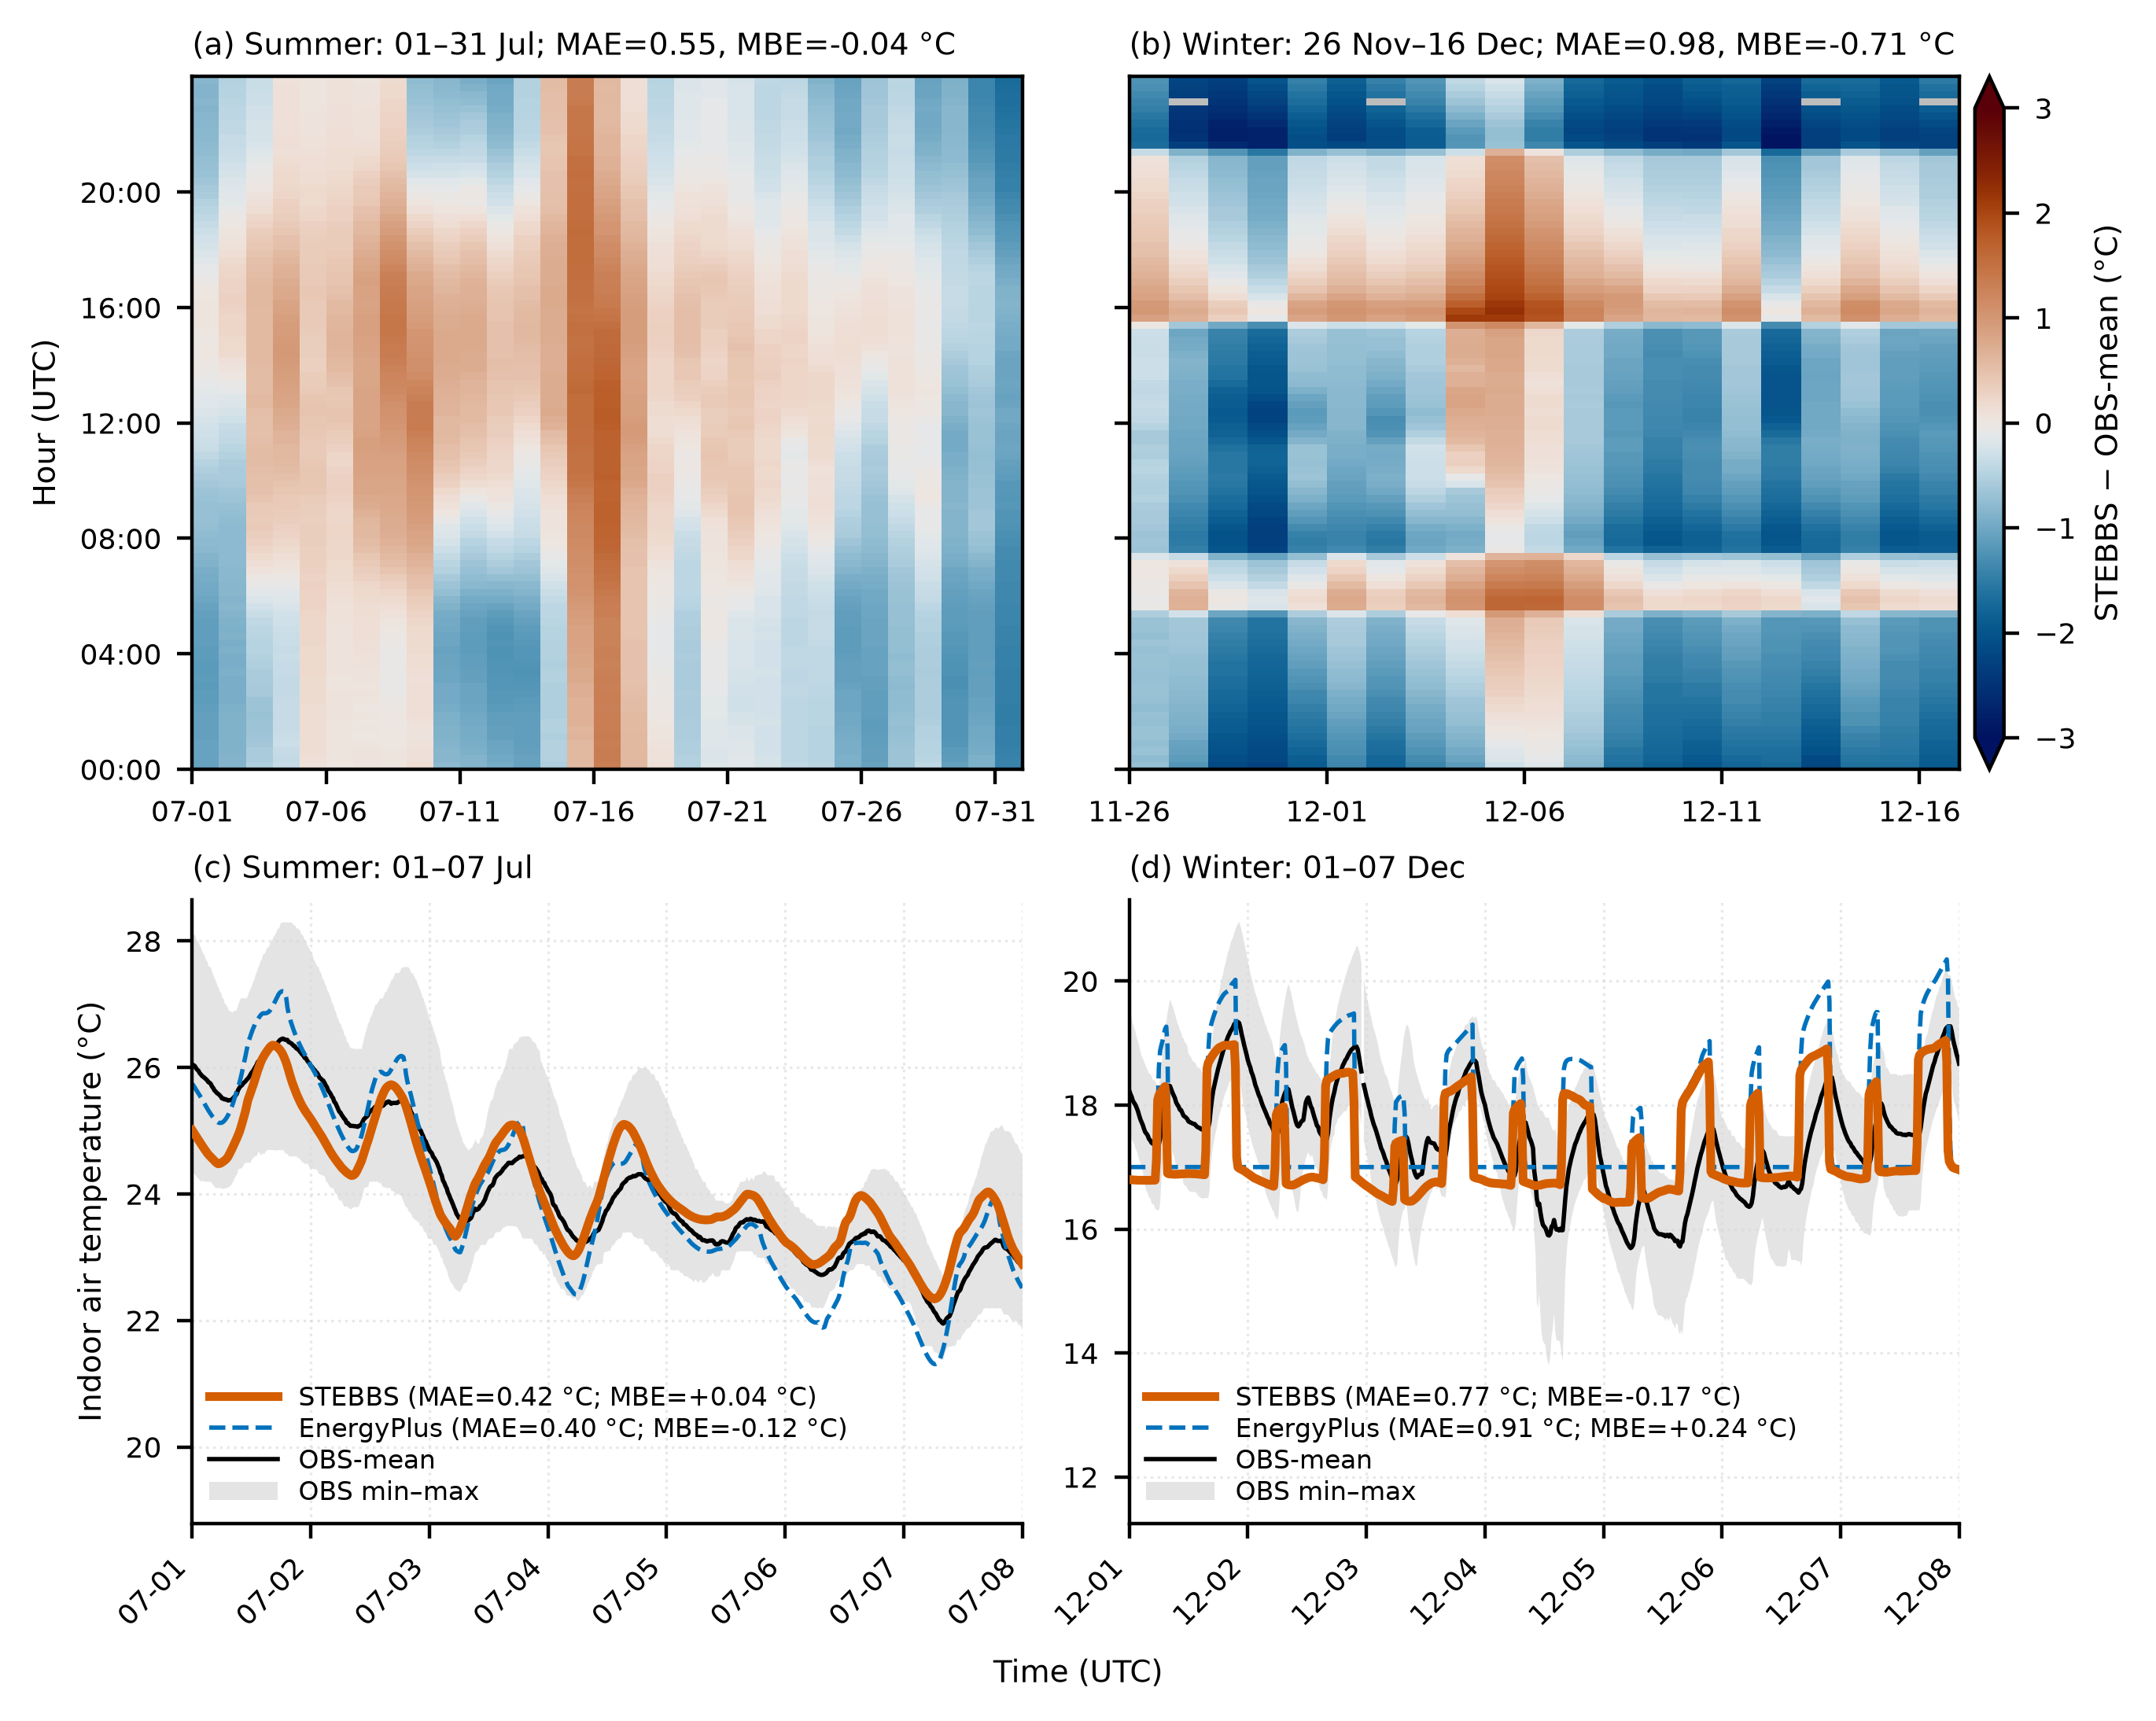

In [9]:
indoor_periods = [
    ("Summer", "2025-07-01", "2025-07-31", "2025-07-01", "2025-07-08"),
    ("Winter", "2025-11-26", "2025-12-16", "2025-12-01", "2025-12-08"),
]
indoor_title_size = 7.0
indoor_style = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.labelsize": 7.0,
    "axes.titlesize": indoor_title_size,
    "legend.fontsize": 7.5,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "figure.labelsize": 7.0,
}
cmap = vik.with_extremes(bad="#BDBDBD")

with plt.rc_context(indoor_style):
    figure_10 = plt.figure(
        figsize=(FIGURE_WIDTH, FIGURE_WIDTH * 0.80),
        dpi=FIGURE_DPI,
        layout="constrained",
    )
    figure_10.get_layout_engine().set(w_pad=0.02)
    layout = figure_10.add_gridspec(
        2, 3, width_ratios=[1, 1, 0.035], height_ratios=[1, 0.9]
    )
    axes_10 = np.array(
        [
            [
                figure_10.add_subplot(layout[0, 0]),
                figure_10.add_subplot(layout[0, 1]),
            ],
            [
                figure_10.add_subplot(layout[1, 0]),
                figure_10.add_subplot(layout[1, 1]),
            ],
        ]
    )
    colourbar_axis = figure_10.add_subplot(layout[0, 2])

    for j, period in enumerate(indoor_periods):
        season, start, end, week_start, week_end = period
        days = pd.date_range(start, end, freq="D", tz="UTC")
        date_edges = pd.date_range(
            days[0], days[-1] + pd.Timedelta(days=1), freq="D"
        )
        index = pd.date_range(
            date_edges[0], date_edges[-1], freq="15min", inclusive="left"
        )
        week_start = pd.Timestamp(week_start, tz="UTC")
        week_end = pd.Timestamp(week_end, tz="UTC")
        errors = bias_for_plot.reindex(index)
        if not errors.notna().any():
            raise ValueError(f"No paired data for {season}")
        grid = errors.to_numpy().reshape(len(days), 96).T
        ax = axes_10[0, j]
        mesh = ax.pcolormesh(
            mdates.date2num(date_edges.to_pydatetime()),
            np.arange(97) / 4,
            np.ma.masked_invalid(grid),
            cmap=cmap,
            vmin=-3,
            vmax=3,
            shading="flat",
            rasterized=True,
        )

        start_label = days[0].strftime(
            "%d" if days[0].month == days[-1].month else "%d %b"
        )
        ax.set_title(
            f"({'ab'[j]}) {season}: {start_label}\N{EN DASH}"
            f"{days[-1]:%d %b}; MAE={errors.abs().mean():.2f}, "
            f"MBE={errors.mean():+.2f} \N{DEGREE SIGN}C",
            loc="left",
            fontsize=indoor_title_size,
            fontweight="normal",
            pad=5,
        )
        ax.set_xlim(date_edges[0], date_edges[-1])
        ax.set_xticks(mdates.date2num(days[::5].to_pydatetime()))
        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%m-%d", tz=timezone.utc)
        )
        ax.set_ylim(0, 24)
        ax.set_yticks(np.arange(0, 24, 4))
        ax.set_yticklabels([f"{hour:02d}:00" for hour in range(0, 24, 4)])
        if j == 1:
            ax.tick_params(labelleft=False)
        ax.grid(False)

        indoor = comparison.loc[
            week_start:week_end,
            ["STEBBS", "EnergyPlus", "OBS_mean", "OBS_min", "OBS_max"],
        ]
        stebbs_pair = indoor[["STEBBS", "OBS_mean"]].dropna()
        ep_pair = indoor[["EnergyPlus", "OBS_mean"]].dropna()
        if stebbs_pair.empty or ep_pair.empty:
            raise ValueError(f"No paired weekly data for {season}")
        stebbs_error = stebbs_pair["STEBBS"] - stebbs_pair["OBS_mean"]
        ep_error = ep_pair["EnergyPlus"] - ep_pair["OBS_mean"]

        ax = axes_10[1, j]
        band = ax.fill_between(
            indoor.index,
            indoor["OBS_min"],
            indoor["OBS_max"],
            color="#D9D9D9",
            alpha=0.7,
            linewidth=0,
            label="OBS min\N{EN DASH}max",
            zorder=1,
        )
        obs_line, = ax.plot(
            indoor.index,
            indoor["OBS_mean"],
            color="black",
            linewidth=1,
            label="OBS-mean",
            zorder=2,
        )
        model_line, = ax.plot(
            indoor.index,
            indoor["STEBBS"],
            color="#D55E00",
            linewidth=2,
            label=(
                f"STEBBS (MAE={stebbs_error.abs().mean():.2f} "
                f"\N{DEGREE SIGN}C; MBE={stebbs_error.mean():+.2f} "
                f"\N{DEGREE SIGN}C)"
            ),
            zorder=3,
        )
        ep_line, = ax.plot(
            indoor.index,
            indoor["EnergyPlus"],
            color="#0072BD",
            linestyle="--",
            linewidth=1,
            label=(
                f"EnergyPlus (MAE={ep_error.abs().mean():.2f} "
                f"\N{DEGREE SIGN}C; MBE={ep_error.mean():+.2f} "
                f"\N{DEGREE SIGN}C)"
            ),
            zorder=2.5,
        )
        lo, hi = indoor.min().min(), indoor.max().max()
        span = max(hi - lo, 1.0)
        ax.set_ylim(lo - 0.36 * span, hi + 0.05 * span)
        ax.legend(
            handles=[model_line, ep_line, obs_line, band],
            loc="lower left",
            fontsize=6,
            frameon=False,
            handlelength=2.6,
            labelspacing=0.2,
            borderpad=0.15,
        )
        week_last_day = week_end - pd.Timedelta(nanoseconds=1)
        ax.set_title(
            f"({'cd'[j]}) {season}: {week_start:%d}"
            f"\N{EN DASH}{week_last_day:%d %b}",
            loc="left",
            fontsize=indoor_title_size,
            fontweight="normal",
            pad=5,
        )
        ax.set_xlim(week_start, week_end)
        ax.xaxis.set_major_locator(mdates.DayLocator(tz=timezone.utc))
        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%m-%d", tz=timezone.utc)
        )
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(True, color="0.85", linestyle=":", linewidth=0.6, alpha=0.6)

    axes_10[0, 0].set_ylabel("Hour (UTC)")
    axes_10[1, 0].set_ylabel("Indoor air temperature (\N{DEGREE SIGN}C)")
    colourbar = figure_10.colorbar(
        mesh,
        cax=colourbar_axis,
        ticks=np.arange(-3, 4),
        extend="both",
    )
    colourbar.set_label("STEBBS \N{MINUS SIGN} OBS-mean (\N{DEGREE SIGN}C)")
    figure_10.supxlabel("Time (UTC)")
    figure_10.savefig(
        FIGURE_DIR / "figure_10.png", dpi=FIGURE_DPI, facecolor="white"
    )
    plt.show()

## Figure 11. Room temperatures

Input: model, mean and room temperatures; output: `figure_11.png`.

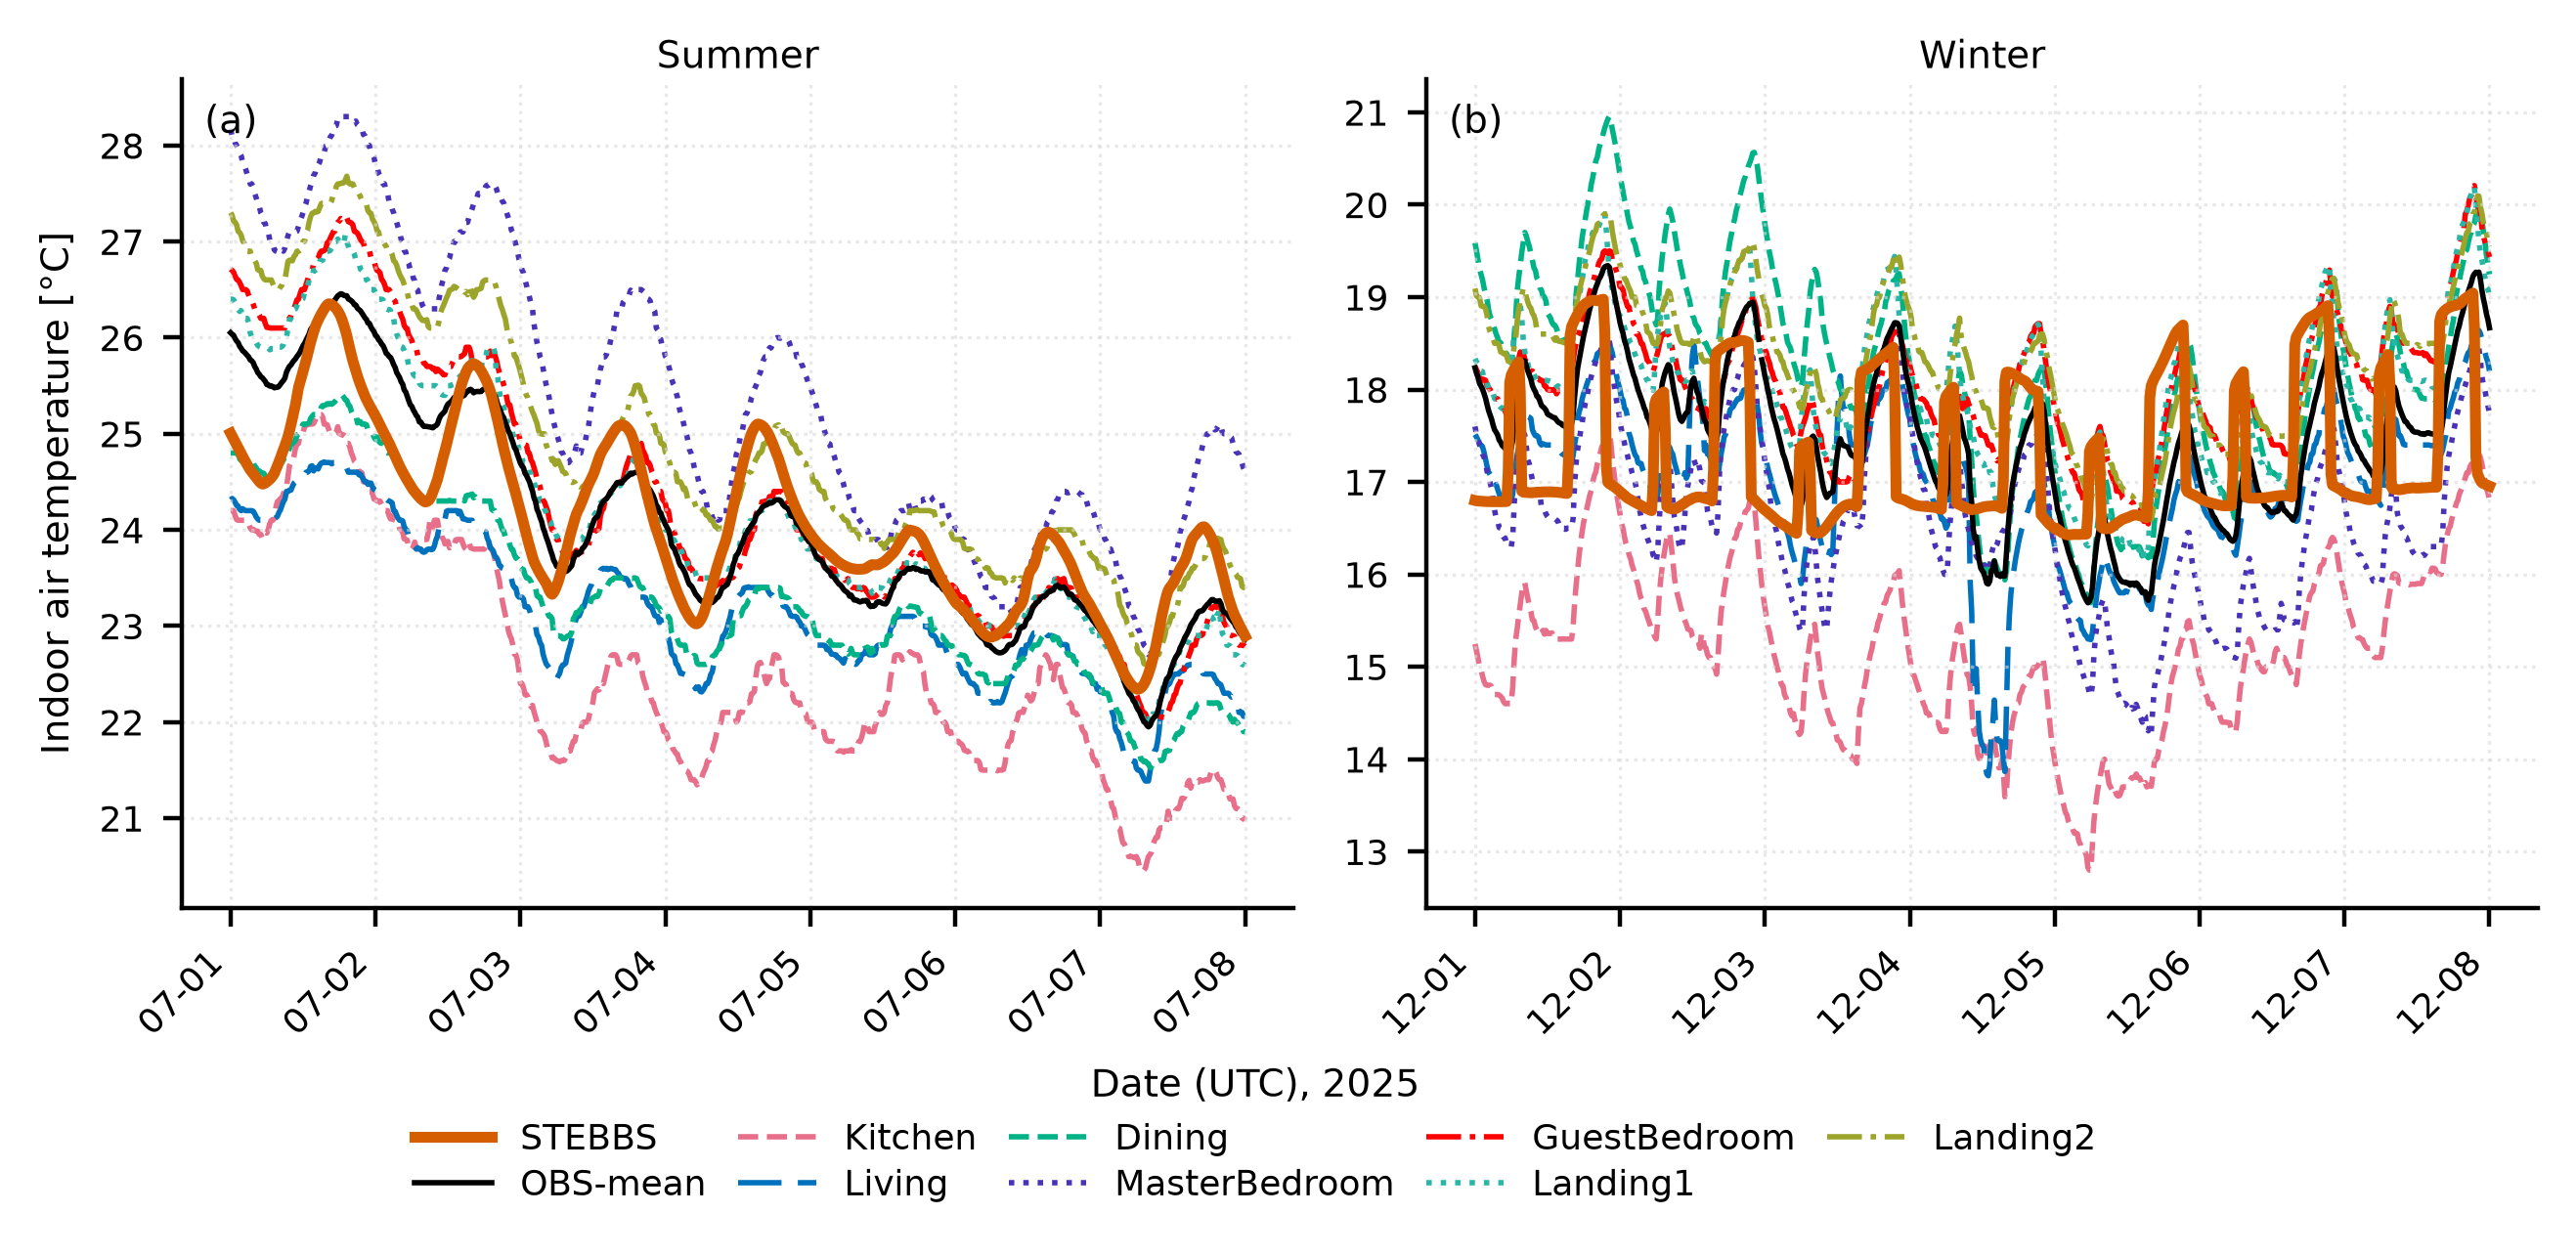

In [10]:
room_styles = {
    "kitchen": ("Kitchen", "#E76F89", "--"),
    "living_room": ("Living", "#0072BD", (0, (8, 3))),
    "dining_room": ("Dining", "#00B386", "--"),
    "master_bedroom": ("MasterBedroom", "#4932B8", ":"),
    "guest_bedroom": ("GuestBedroom", "#FF0000", "-."),
    "landing1": ("Landing1", "#29B6A6", ":"),
    "landing2": ("Landing2", "#9CA52A", "-."),
}
periods = [
    ("Summer", "2025-07-01", "2025-07-08", "(a)"),
    ("Winter", "2025-12-01", "2025-12-08", "(b)"),
]
room_figure_style = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 7,
    "axes.titleweight": "normal",
    "axes.titlepad": 2,
    "axes.labelsize": 7,
    "figure.labelsize": 7,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "legend.fontsize": 6.5,
}

with plt.rc_context(room_figure_style):
    figure_11, axes_11 = plt.subplots(
        1,
        2,
        figsize=(FIGURE_WIDTH, FIGURE_WIDTH * 5.2 / 11),
        dpi=FIGURE_DPI,
    )
    figure_11.subplots_adjust(
        left=0.09, right=0.99, bottom=0.27, top=0.94, wspace=0.12
    )

    for ax, period in zip(axes_11, periods):
        season, start, end, panel = period
        start = pd.Timestamp(start, tz="UTC")
        end = pd.Timestamp(end, tz="UTC")
        data = plot_data.loc[start:end]

        room_lines = []
        for column, style in room_styles.items():
            label, colour, linestyle = style
            line, = ax.plot(
                data.index,
                data[column],
                label=label,
                color=colour,
                linestyle=linestyle,
                linewidth=1,
                zorder=1,
            )
            room_lines.append(line)

        obs_line, = ax.plot(
            data.index,
            data["OBS_mean"],
            label="OBS-mean",
            color="black",
            linestyle="-",
            linewidth=1,
            zorder=3,
        )
        model_line, = ax.plot(
            data.index,
            data["STEBBS"],
            label="STEBBS",
            color="#D55E00",
            linestyle="-",
            linewidth=2,
            zorder=4,
        )

        ax.set_title(season)
        ax.text(
            0.02,
            0.97,
            panel,
            transform=ax.transAxes,
            va="top",
            fontsize=7,
        )
        ax.set_xlim(
            start - pd.Timedelta(hours=8), end + pd.Timedelta(hours=8)
        )
        ax.xaxis.set_major_locator(mdates.DayLocator(tz=timezone.utc))
        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%m-%d", tz=timezone.utc)
        )
        ax.yaxis.set_major_locator(MultipleLocator(1))
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        ax.grid(True, color="0.85", linestyle=":", linewidth=0.6, alpha=0.6)
        ax.spines[["top", "right"]].set_visible(False)

    axes_11[0].set_ylabel("Indoor air temperature [\N{DEGREE SIGN}C]")
    figure_11.supxlabel("Date (UTC), 2025", y=0.11)
    figure_11.legend(
        handles=[model_line, obs_line, *room_lines],
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=5,
        frameon=False,
        handlelength=2.2,
        columnspacing=0.9,
        labelspacing=0.3,
    )
    figure_11.savefig(FIGURE_DIR / "figure_11.png", dpi=FIGURE_DPI)
    plt.show()

## Figure 12: building energy balance

EnergyPlus fluxes use a 56.39 m2 footprint, cooling COP 3.4 and heating
efficiency 0.90. Positive $Q^*$ and $Q_{EC}$ enter the building; positive
$Q_H$, $Q_{BAE}$ and $Q_{Waste}$ leave it; positive $\Delta Q_S$ is storage.
Outdoor radiation and convection include all four exposed opaque surfaces
(including `WALL_LEFT_REAR_EXPOSED`) and all four windows. Storage includes
all seven building surfaces, both internal-mass objects and zone air. The
ground floor and adiabatic party walls contribute to storage, not outdoor
radiation or convection.

Inputs are the full Evaluation 0 five-minute dataframes. The models are paired
before right-labelled 15-minute means are formed, and every retained mean has
all three native records for every flux. No spin-up period is removed. Seasons
use interval midpoints, so the midnight interval belongs to the previous day.
Lines and ribbons show the seasonal mean and interquartile range. Panel MAE
and MBE (STEBBS minus EnergyPlus) use the paired raw 15-minute values, not the
mean diurnal curves. Output: `figure_12.png`.

In [11]:
EP_AREA_M2 = 56.39
COOLING_COP = 3.4
HEATING_EFFICIENCY = 0.90

exterior_opaque = ["WALL_BACK", "WALL_FRONT", "ROOF", "WALL_LEFT_REAR_EXPOSED"]
exterior_windows = ["FACE 4", "FACE 5", "FACE 8", "FACE 9"]
storage_surfaces = [
    "WALL_REAR1", "WALL_BACK", "WALL_REAR2", "WALL_FRONT",
    "FLOOR", "ROOF", "INTERNALWALL", "CEILINGFLOOR", "WALL_LEFT_REAR_EXPOSED",
]

outside_solar = "Surface Outside Face Solar Radiation Heat Gain Rate"
window_absorbed = "Surface Window Total Glazing Layers Absorbed Solar Radiation Rate"
shade_absorbed = "Surface Window Shading Device Absorbed Solar Radiation Rate"
window_transmitted = "Surface Window Transmitted Solar Radiation Rate"
window_back_out = "Surface Window Shortwave from Zone Back Out Window Heat Transfer Rate"
outside_longwave = "Surface Outside Face Net Thermal Radiation Heat Gain Rate"
outside_convection = "Surface Outside Face Convection Heat Gain Rate"
surface_storage = "Surface Heat Storage Rate"

opaque_solar_columns = [f"{name}:{outside_solar} [W](TimeStep)" for name in exterior_opaque]
window_absorbed_columns = [f"{name}:{window_absorbed} [W](TimeStep)" for name in exterior_windows]
shade_absorbed_columns = [f"{name}:{shade_absorbed} [W](TimeStep)" for name in exterior_windows]
window_transmitted_columns = [f"{name}:{window_transmitted} [W](TimeStep)" for name in exterior_windows]
window_back_out_columns = [f"{name}:{window_back_out} [W](TimeStep)" for name in exterior_windows]
radiating_surfaces = exterior_opaque + exterior_windows
longwave_columns = [f"{name}:{outside_longwave} [W](TimeStep)" for name in radiating_surfaces]
convection_columns = [f"{name}:{outside_convection} [W](TimeStep)" for name in radiating_surfaces]
storage_columns = [f"{name}:{surface_storage} [W](TimeStep)" for name in storage_surfaces]

heating_column = (
    "ZONE HVAC IDEAL LOADS AIR SYSTEM:"
    "Zone Ideal Loads Supply Air Sensible Heating Rate [W](TimeStep)"
)
cooling_column = (
    "ZONE HVAC IDEAL LOADS AIR SYSTEM:"
    "Zone Ideal Loads Supply Air Sensible Cooling Rate [W](TimeStep)"
)
internal_column = "THERMAL ZONE 1:Zone Total Internal Total Heating Rate [W](TimeStep)"
air_storage_column = "THERMAL ZONE 1:Zone Air Heat Balance Air Energy Storage Rate [W](TimeStep)"
exfiltration_column = "THERMAL ZONE 1:Zone Exfiltration Sensible Heat Transfer Rate [W](TimeStep)"

ep_energy = ep_outputs["Evaluation_0"]
absorbed_solar = (
    ep_energy[opaque_solar_columns].sum(axis=1)
    + ep_energy[window_absorbed_columns].sum(axis=1)
    + ep_energy[shade_absorbed_columns].sum(axis=1)
    + ep_energy[window_transmitted_columns].sum(axis=1)
    - ep_energy[window_back_out_columns].sum(axis=1)
)
net_longwave = ep_energy[longwave_columns].sum(axis=1)
useful_heating = ep_energy[heating_column]
useful_cooling = ep_energy[cooling_column]

ep_flux_5min = pd.DataFrame(index=ep_energy.index)
ep_flux_5min["Qstar"] = absorbed_solar + net_longwave
ep_flux_5min["QEC"] = (
    useful_heating / HEATING_EFFICIENCY
    + useful_cooling / COOLING_COP
    + ep_energy[internal_column]
)
# EnergyPlus exterior convection is positive into the surface, hence the minus.
ep_flux_5min["QH"] = -ep_energy[convection_columns].sum(axis=1)
ep_flux_5min["QS"] = (
    ep_energy[storage_columns].sum(axis=1) + ep_energy[air_storage_column]
)
ep_flux_5min["QBAE"] = ep_energy[exfiltration_column]
ep_flux_5min["QWaste"] = (
    useful_heating * (1 / HEATING_EFFICIENCY - 1)
    + useful_cooling * (1 + 1 / COOLING_COP)
)
ep_flux_5min = ep_flux_5min / EP_AREA_M2

flux_columns = ["Qstar", "QEC", "QH", "QS", "QBAE", "QWaste"]
stebbs_flux_5min = stebbs_outputs["Evaluation_0"][[
    "QN_bldg_FA", "QEC_bldg_FA", "QH_bldg_FA",
    "QS_total_FA", "QBAE_bldg_FA", "QWaste_bldg_FA",
]].rename(columns={
    "QN_bldg_FA": "Qstar",
    "QEC_bldg_FA": "QEC",
    "QH_bldg_FA": "QH",
    "QS_total_FA": "QS",
    "QBAE_bldg_FA": "QBAE",
    "QWaste_bldg_FA": "QWaste",
})

paired_flux_5min = pd.concat(
    {"STEBBS": stebbs_flux_5min, "EnergyPlus": ep_flux_5min[flux_columns]},
    axis=1,
    join="inner",
).dropna()
quarter_hour_flux = paired_flux_5min.resample(
    "15min", closed="right", label="right"
)
paired_flux_15min = quarter_hour_flux.mean().where(
    quarter_hour_flux.count() == 3
).dropna()

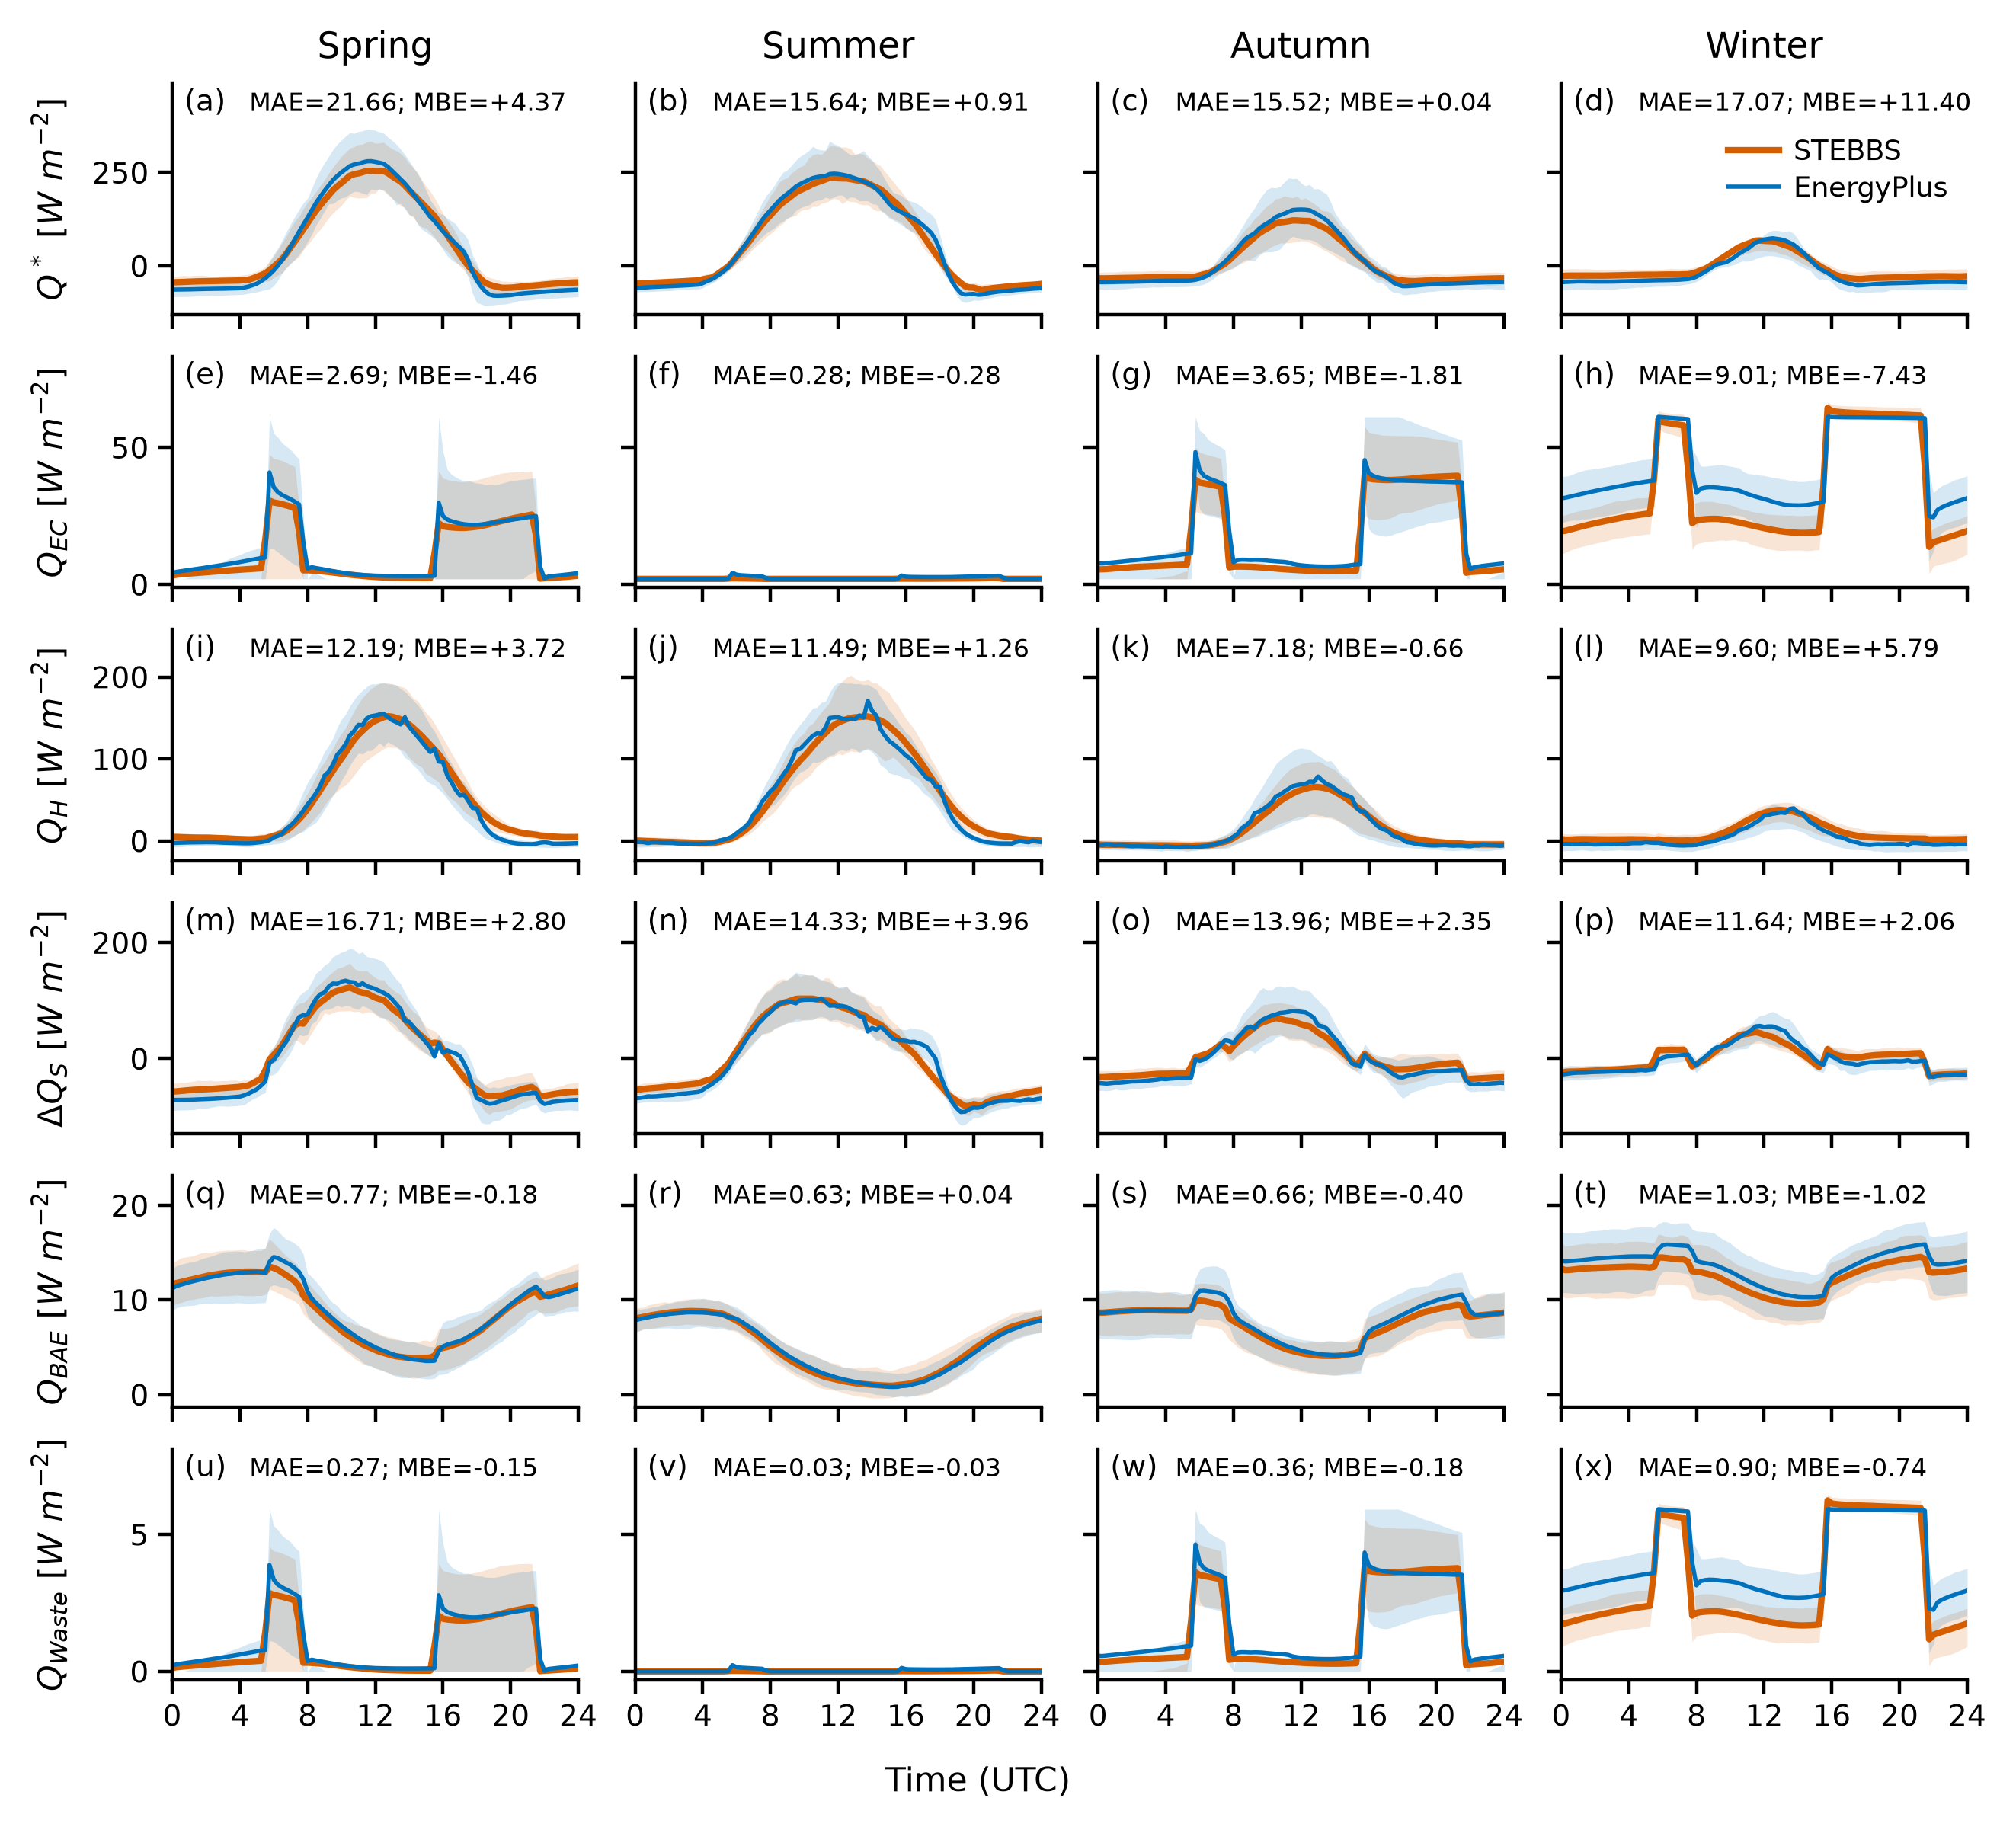

In [12]:
SEASON_MONTHS = {
    "Spring": (3, 4, 5),
    "Summer": (6, 7, 8),
    "Autumn": (9, 10, 11),
    "Winter": (12, 1, 2),
}
FLUX_LABELS = {
    "Qstar": r"$Q^*\ [W\ m^{-2}]$",
    "QEC": r"$Q_{EC}\ [W\ m^{-2}]$",
    "QH": r"$Q_H\ [W\ m^{-2}]$",
    "QS": r"$\Delta Q_S\ [W\ m^{-2}]$",
    "QBAE": r"$Q_{BAE}\ [W\ m^{-2}]$",
    "QWaste": r"$Q_{Waste}\ [W\ m^{-2}]$",
}
MODEL_STYLES = {
    "STEBBS": {"color": "#D55E00", "linewidth": 1.5},
    "EnergyPlus": {"color": "#0072BD", "linewidth": 1.0},
}

interval_midpoint = paired_flux_15min.index - pd.Timedelta(minutes=7.5)
seasonal_stat_records = []
for flux_name in flux_columns:
    for season, months in SEASON_MONTHS.items():
        seasonal_pair = paired_flux_15min.loc[
            interval_midpoint.month.isin(months),
            [("STEBBS", flux_name), ("EnergyPlus", flux_name)],
        ].dropna()
        difference = (
            seasonal_pair[("STEBBS", flux_name)]
            - seasonal_pair[("EnergyPlus", flux_name)]
        )
        seasonal_stat_records.append({
            "flux": flux_name,
            "season": season,
            "N": len(difference),
            "MAE": difference.abs().mean(),
            "MBE": difference.mean(),
        })
seasonal_flux_statistics = pd.DataFrame(seasonal_stat_records).set_index(
    ["flux", "season"]
)

fig, axes = plt.subplots(
    len(flux_columns), len(SEASON_MONTHS),
    figsize=(FIGURE_WIDTH, FIGURE_WIDTH * 0.9),
    dpi=FIGURE_DPI,
    sharex=True,
    sharey="row",
)
fig.subplots_adjust(
    left=0.105, right=0.985, bottom=0.075, top=0.945,
    hspace=0.18, wspace=0.14,
)

seasonal_flux_profiles = {}
for column_number, (season, months) in enumerate(SEASON_MONTHS.items()):
    season_mask = interval_midpoint.month.isin(months)
    for row_number, flux_name in enumerate(flux_columns):
        ax = axes[row_number, column_number]
        panel_label = chr(ord("a") + row_number * len(SEASON_MONTHS) + column_number)
        ax.text(
            0.03, 0.88, f"({panel_label})", transform=ax.transAxes,
            ha="left", va="baseline", fontsize=7, zorder=5,
        )

        for model_name, style in MODEL_STYLES.items():
            seasonal_series = paired_flux_15min.loc[
                season_mask, (model_name, flux_name)
            ]
            quarter_end = seasonal_series.index.hour * 4 + seasonal_series.index.minute // 15
            quarter_end = np.where(quarter_end == 0, 96, quarter_end)
            grouped = seasonal_series.groupby(quarter_end)
            profile = pd.DataFrame({
                "mean": grouped.mean(),
                "p25": grouped.quantile(0.25),
                "p75": grouped.quantile(0.75),
            })
            profile.index = profile.index / 4
            if 24.0 in profile.index:
                profile = pd.concat([profile.loc[[24.0]].set_axis([0.0]), profile])
            seasonal_flux_profiles[(season, model_name, flux_name)] = profile
            x = profile.index.to_numpy(dtype=float)
            ax.fill_between(
                x, profile["p25"].to_numpy(), profile["p75"].to_numpy(),
                color=style["color"], alpha=0.16, linewidth=0,
            )
            ax.plot(x, profile["mean"].to_numpy(), label=model_name, **style)

        statistic = seasonal_flux_statistics.loc[(flux_name, season)]
        displayed_mbe = 0.0 if abs(statistic["MBE"]) < 0.005 else statistic["MBE"]
        ax.text(
            0.19, 0.88,
            f"MAE={statistic['MAE']:.2f}; MBE={displayed_mbe:+.2f}",
            transform=ax.transAxes, ha="left", va="baseline", fontsize=6,
            zorder=5,
        )
        ax.set_xlim(0, 24)
        ax.set_xticks(np.arange(0, 25, 4))
        ax.tick_params(axis="both", labelsize=7, pad=2)
        ax.spines[["top", "right"]].set_visible(False)
        if column_number == 0:
            ax.set_ylabel(FLUX_LABELS[flux_name], fontsize=8, labelpad=5)
    axes[0, column_number].set_title(season, fontsize=8.5, fontweight="normal", pad=6)

# Reserve one annotation line above the curves, with common limits in each row.
for row_axes in axes:
    lower, upper = row_axes[0].get_ylim()
    row_axes[0].set_ylim(lower, lower + (upper - lower) / 0.84)

axes[0, 3].legend(
    loc="upper right", bbox_to_anchor=(0.98, 0.81), frameon=False,
    fontsize=6.7, handlelength=1.8, handletextpad=0.5,
    borderaxespad=0, labelspacing=0.3,
)
fig.supxlabel("Time (UTC)", fontsize=8, y=0.01)
fig.align_ylabels(axes[:, 0])
fig.savefig(FIGURE_DIR / "figure_12.png", dpi=FIGURE_DPI, facecolor="white")
plt.show()

## Figure 13: building anthropogenic heat emission

This is the occupied-minus-unoccupied change in net outward heat release:

$$Q_{F,B}=\Delta L_{net}+\Delta Q_H+\Delta Q_{BAE}+\Delta Q_{Waste}.$$

$L_{net}$ is the sum of the wall, roof and window net-longwave components.
These components are positive outwards and already use footprint-area units;
$Q^*$ is not included. The occupied and unoccupied counterfactuals also differ
in curtain shading, so the result is not a fully isolated energy-use effect.
Full-year paired data are retained without a spin-up exclusion. Fifteen-minute
means again require all three five-minute records, and midpoint seasons assign
midnight intervals to the preceding day. Output: `figure_13.png`.

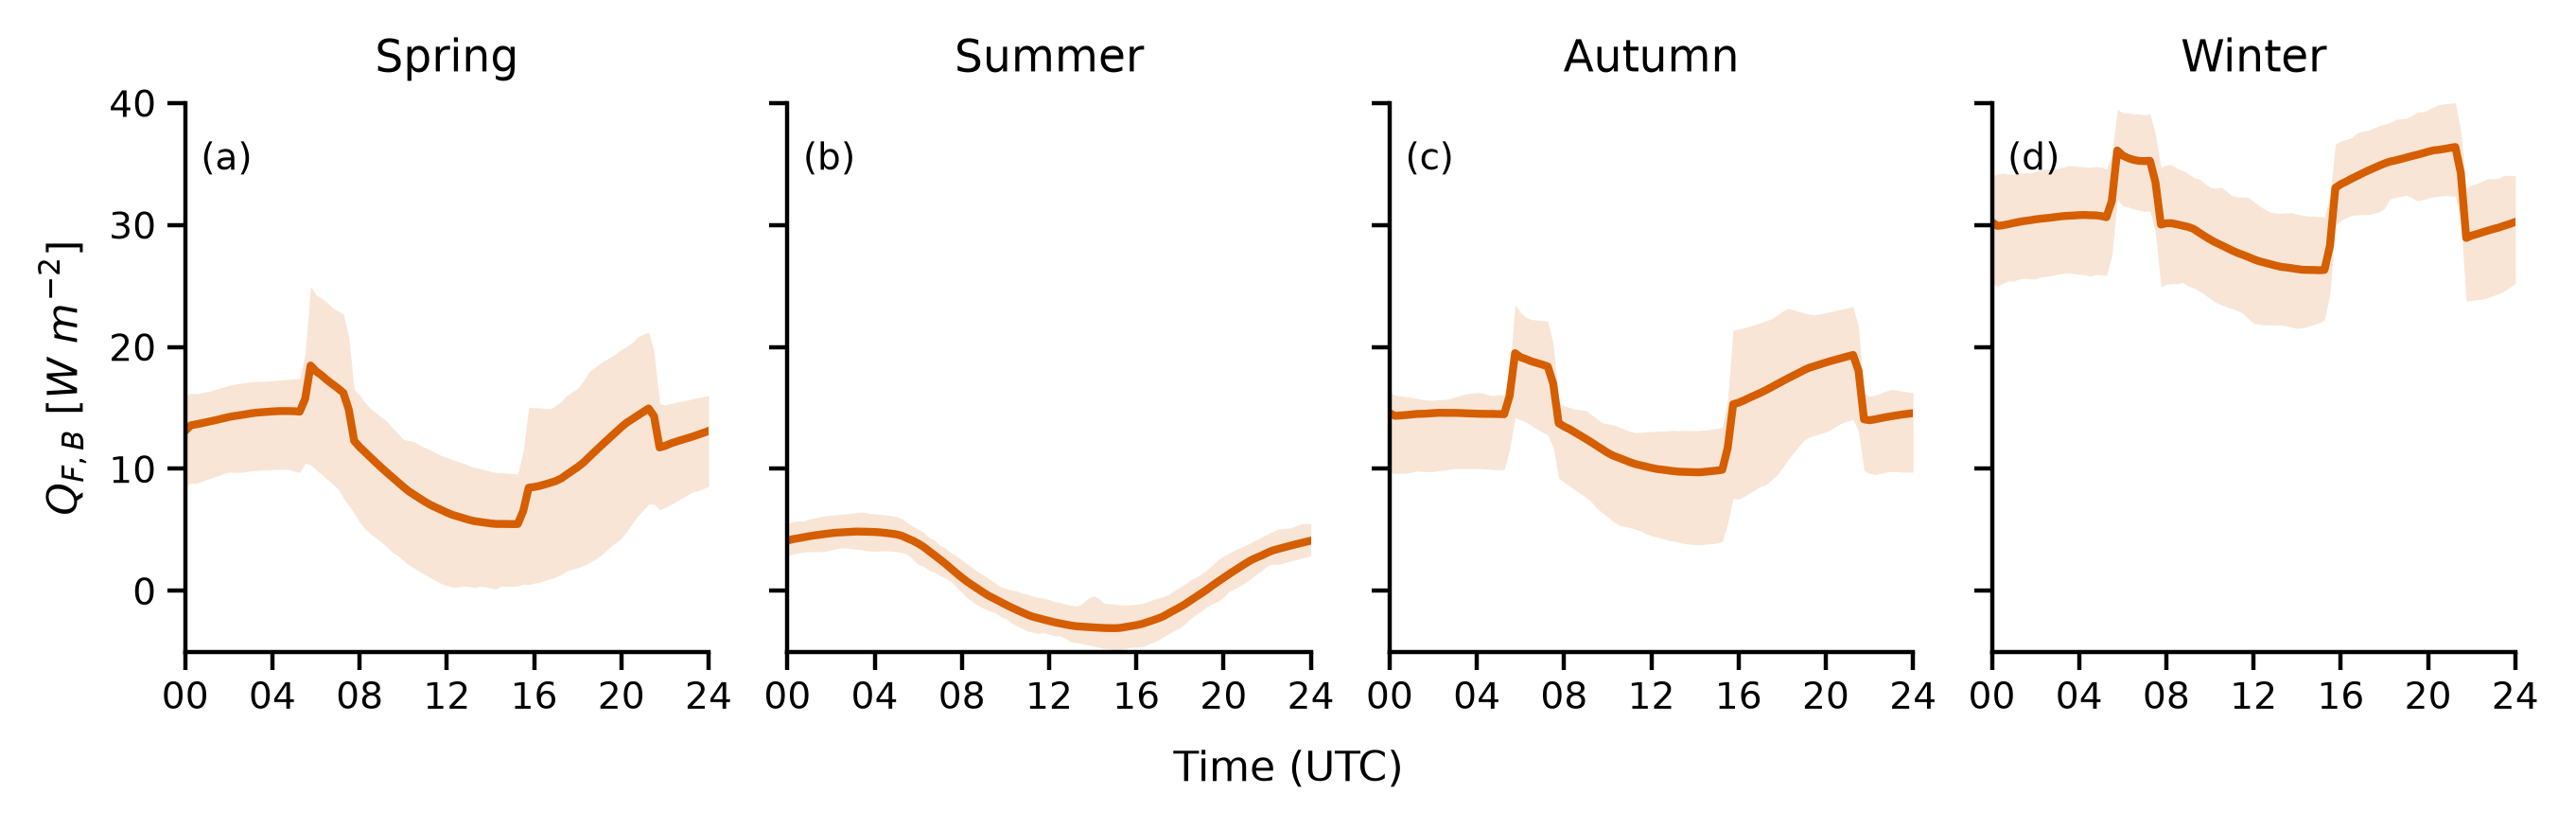

In [13]:
outward_longwave_columns = [
    "Qlw_net_wall_FA", "Qlw_net_roof_FA", "Qlw_net_window_FA",
]
outward_heat_columns = [
    "QH_bldg_FA", "QBAE_bldg_FA", "QWaste_bldg_FA",
]
heat_release_columns = outward_longwave_columns + outward_heat_columns
occupied_heat = stebbs_outputs["Evaluation_0"][heat_release_columns]
unoccupied_heat = stebbs_unoccupied[heat_release_columns]
paired_heat_5min = pd.concat(
    {"occupied": occupied_heat, "unoccupied": unoccupied_heat},
    axis=1,
    join="inner",
).dropna()

heat_change_5min = (
    paired_heat_5min["occupied"] - paired_heat_5min["unoccupied"]
)
anthropogenic_heat_5min = (
    paired_heat_5min["occupied"][outward_longwave_columns].sum(
        axis=1, min_count=3
    )
    - paired_heat_5min["unoccupied"][outward_longwave_columns].sum(
        axis=1, min_count=3
    )
    + heat_change_5min["QH_bldg_FA"]
    + heat_change_5min["QBAE_bldg_FA"]
    + heat_change_5min["QWaste_bldg_FA"]
).rename("QF_B")
quarter_hour_heat = anthropogenic_heat_5min.resample(
    "15min", closed="right", label="right"
)
anthropogenic_heat_15min = quarter_hour_heat.mean().where(
    quarter_hour_heat.count() == 3
).dropna()

anthropogenic_midpoint = (
    anthropogenic_heat_15min.index - pd.Timedelta(minutes=7.5)
)
fig, axes = plt.subplots(
    1, 4,
    figsize=(FIGURE_WIDTH, FIGURE_WIDTH * 0.31),
    dpi=FIGURE_DPI,
    sharex=True,
    sharey=True,
    layout="constrained",
)

anthropogenic_heat_profiles = {}
for panel_number, (ax, (season, months)) in enumerate(
    zip(axes, SEASON_MONTHS.items())
):
    seasonal_heat = anthropogenic_heat_15min[
        anthropogenic_midpoint.month.isin(months)
    ]
    quarter_end = seasonal_heat.index.hour * 4 + seasonal_heat.index.minute // 15
    quarter_end = np.where(quarter_end == 0, 96, quarter_end)
    grouped = seasonal_heat.groupby(quarter_end)
    profile = pd.DataFrame({
        "mean": grouped.mean(),
        "p25": grouped.quantile(0.25),
        "p75": grouped.quantile(0.75),
    })
    profile.index = profile.index / 4
    if 24.0 in profile.index:
        profile = pd.concat([profile.loc[[24.0]].set_axis([0.0]), profile])
    anthropogenic_heat_profiles[season] = profile

    x = profile.index.to_numpy(dtype=float)
    ax.fill_between(
        x, profile["p25"].to_numpy(), profile["p75"].to_numpy(),
        color="#D55E00", alpha=0.16, linewidth=0,
    )
    ax.plot(x, profile["mean"].to_numpy(), color="#D55E00", linewidth=1.5)
    ax.set_title(season, fontsize=8.5, fontweight="normal")
    ax.text(
        0.03, 0.93, f"({'abcd'[panel_number]})",
        transform=ax.transAxes, va="top", fontsize=7,
    )
    ax.set_xlim(0, 24)
    ax.set_ylim(-5, 40)
    ax.set_xticks(np.arange(0, 25, 4))
    ax.set_xticklabels([f"{hour:02d}" for hour in range(0, 25, 4)])
    ax.tick_params(axis="both", labelsize=7, pad=2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel(r"$Q_{F,B}\ [W\ m^{-2}]$", fontsize=8)
fig.supxlabel("Time (UTC)", fontsize=8)
fig.savefig(FIGURE_DIR / "figure_13.png", dpi=FIGURE_DPI, facecolor="white")
plt.show()

## Figure 14: Annual indoor temperatures

Input: interval-ending 15-minute STEBBS and EnergyPlus case temperatures. Output:
`figure_14.png` and paired Evaluation_0 statistics. The first five interval-start
days are excluded; the final midnight endpoint is the last interval of 31 December.
Colour limits do not clip the stored values or statistics.

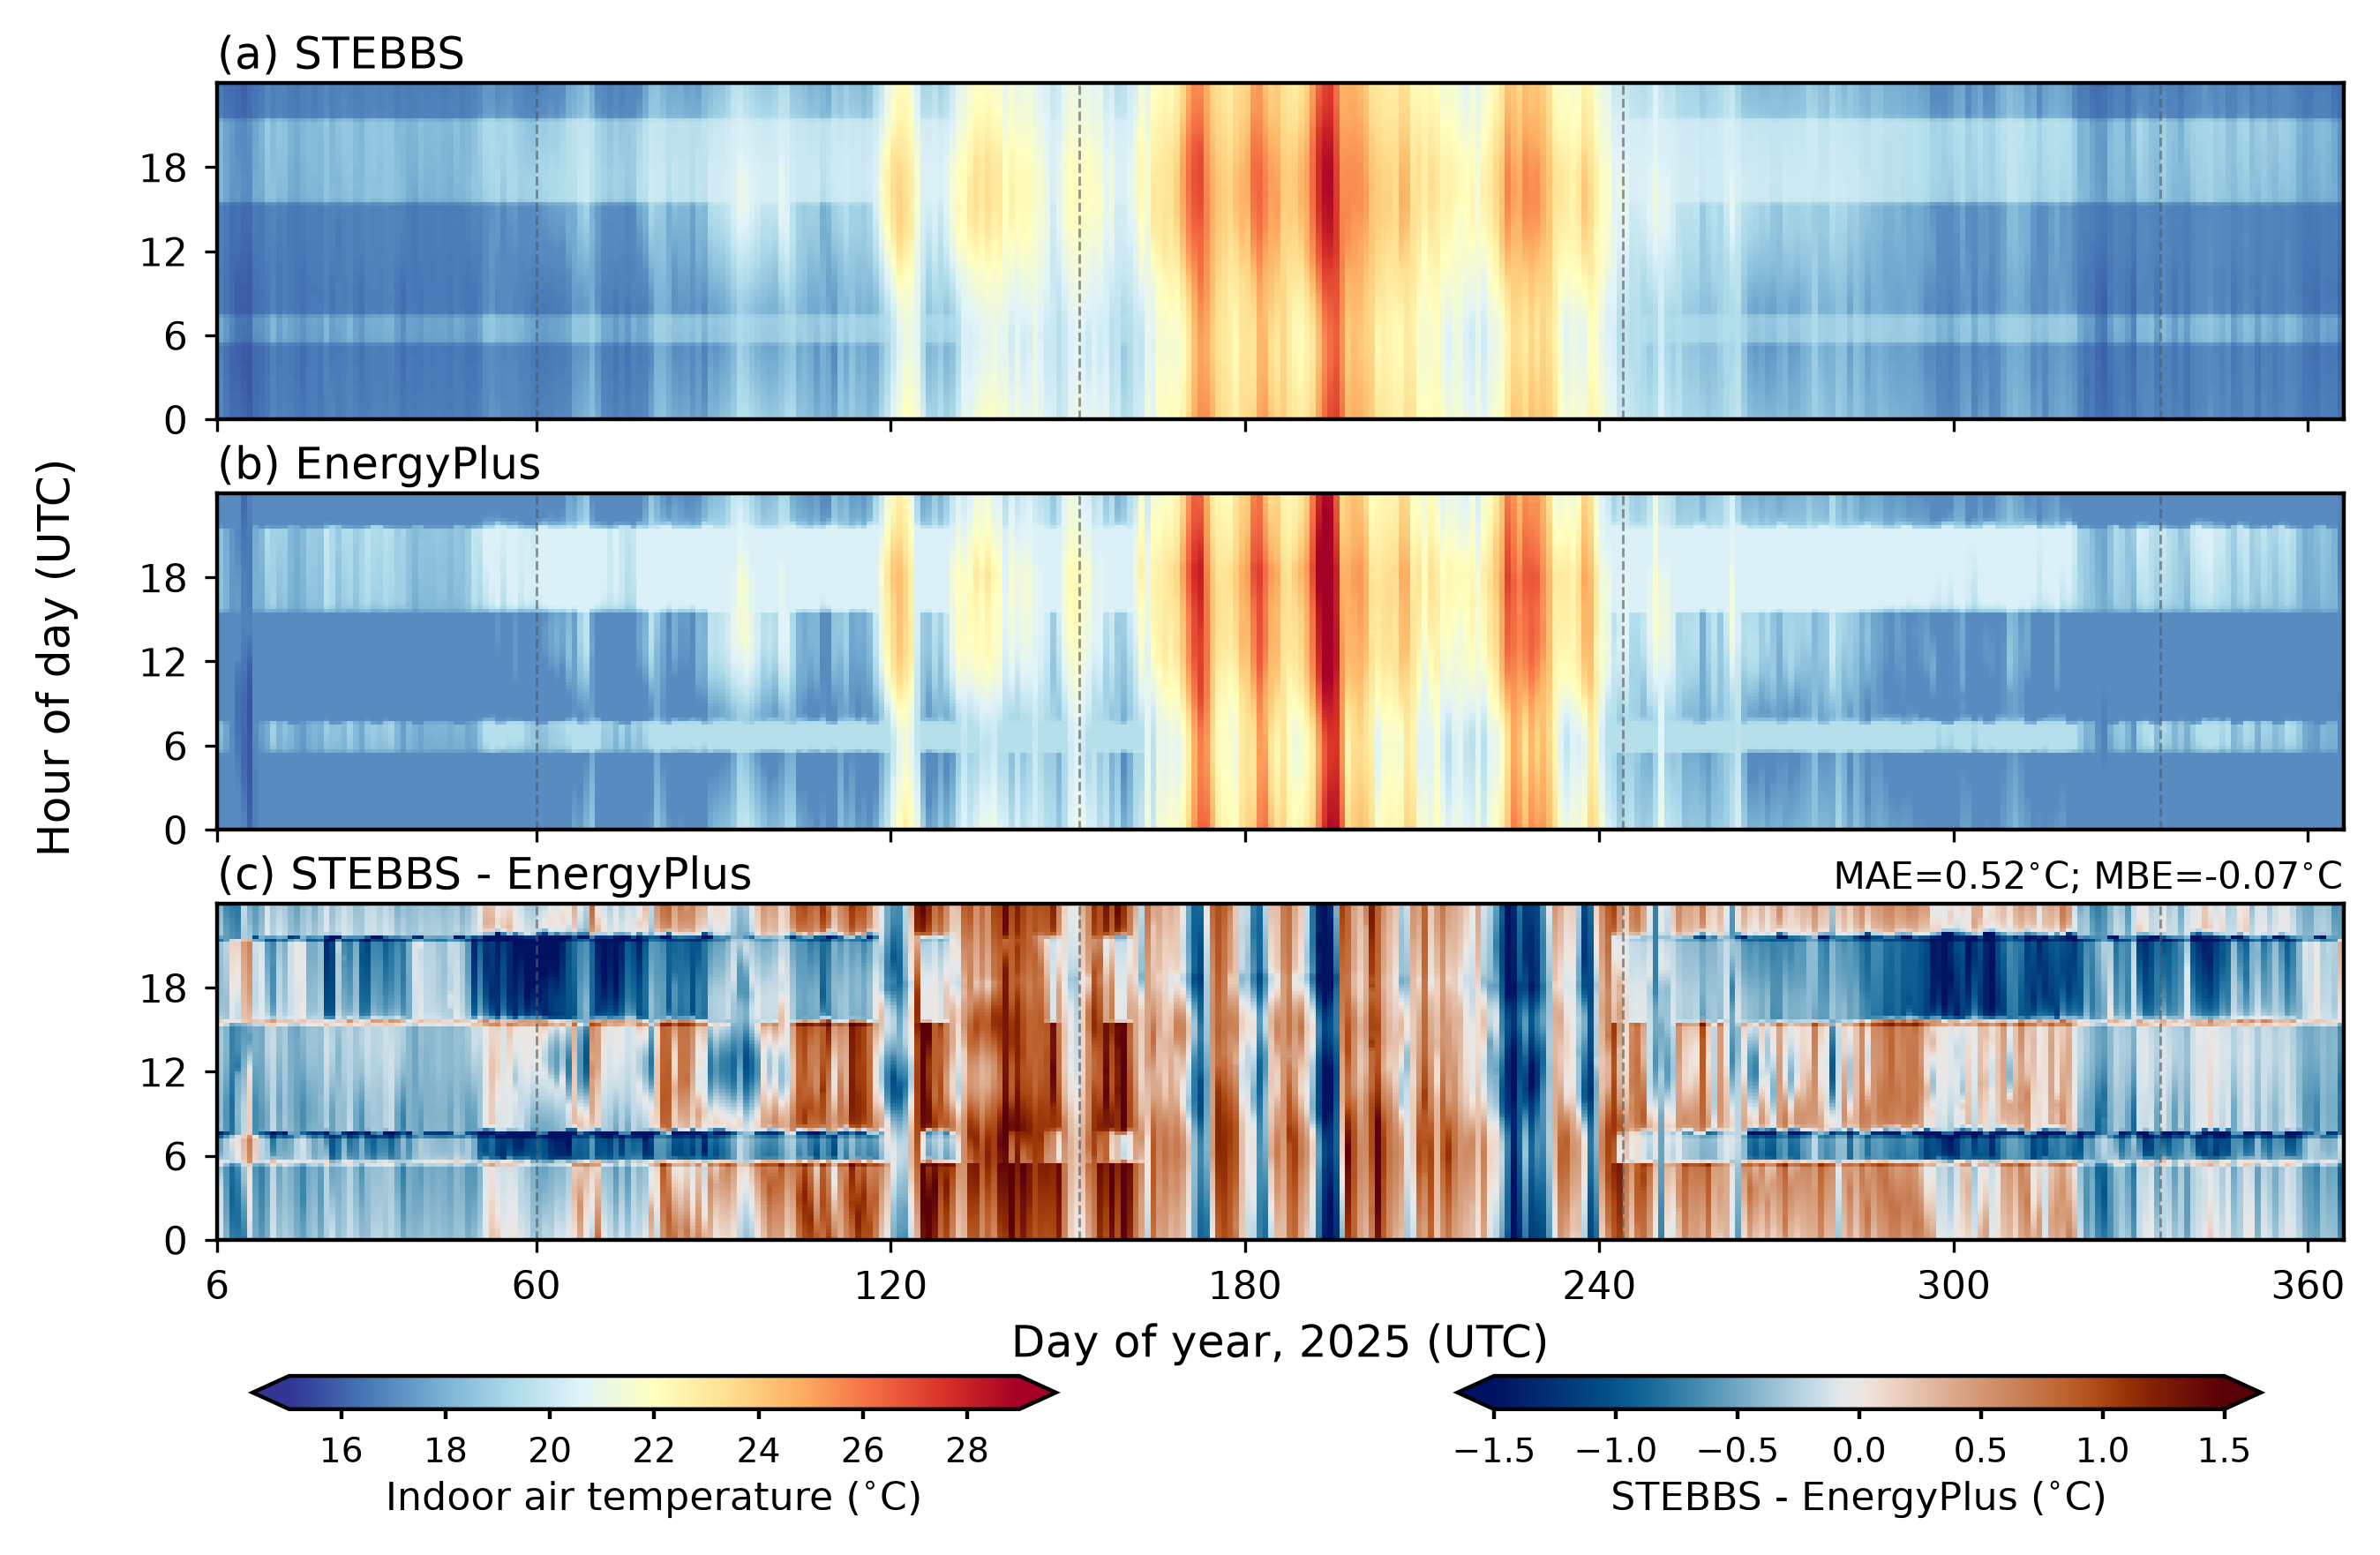

In [14]:
annual_index = pd.date_range(
    f"{YEAR}-01-06 00:15", f"{YEAR + 1}-01-01 00:00",
    freq="15min", tz="UTC", name="timestamp_utc",
)
annual_temperature = pd.concat(
    {
        "STEBBS": stebbs_temperature.reindex(annual_index).reindex(columns=CASES),
        "EnergyPlus": ep_temperature.reindex(annual_index).reindex(columns=CASES),
    },
    axis=1,
)
annual_temperature.columns.names = ["model", "case"]

evaluation_0_temperature = annual_temperature.loc[
    :, [("STEBBS", "Evaluation_0"), ("EnergyPlus", "Evaluation_0")]
].copy()
evaluation_0_temperature.columns = ["STEBBS", "EnergyPlus"]
evaluation_0_temperature["difference"] = (
    evaluation_0_temperature["STEBBS"]
    - evaluation_0_temperature["EnergyPlus"]
)
paired_temperature_difference = evaluation_0_temperature["difference"].dropna()
if paired_temperature_difference.empty:
    raise ValueError("No paired Evaluation_0 temperatures after the spin-up period")
annual_temperature_statistics = pd.Series(
    {
        "paired_intervals": len(paired_temperature_difference),
        "MAE_C": paired_temperature_difference.abs().mean(),
        "MBE_C": paired_temperature_difference.mean(),
        "RMSE_C": np.sqrt((paired_temperature_difference ** 2).mean()),
        "difference_min_C": paired_temperature_difference.min(),
        "difference_max_C": paired_temperature_difference.max(),
    },
    name="Evaluation_0",
)

annual_days = pd.date_range(
    f"{YEAR}-01-06", f"{YEAR + 1}-01-01", freq="D", tz="UTC", inclusive="left"
)
day_edges = np.arange(annual_days[0].dayofyear, annual_days[-1].dayofyear + 2)
hour_edges = np.arange(97) / 4
season_boundaries = [
    pd.Timestamp(f"{YEAR}-{month:02d}-01").dayofyear for month in [3, 6, 9, 12]
]
day_ticks = [annual_days[0].dayofyear, 60, 120, 180, 240, 300, 360]

figure_style = {
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.labelsize": 9,
}
absolute_cmap = plt.get_cmap("RdYlBu_r").with_extremes(bad="#BDBDBD")
difference_cmap = vik.with_extremes(bad="#BDBDBD")

with plt.rc_context(figure_style):
    figure_14, axes_14 = plt.subplots(
        3, 1,
        figsize=(FIGURE_WIDTH, FIGURE_WIDTH * 0.64),
        dpi=FIGURE_DPI,
        sharex=True,
        sharey=True,
    )
    figure_14.subplots_adjust(
        left=0.085, right=0.985, bottom=0.19, top=0.955, hspace=0.22
    )
    for axis, model, letter in zip(
        axes_14[:2], ["STEBBS", "EnergyPlus"], ["a", "b"]
    ):
        temperature_matrix = annual_temperature[
            model, "Evaluation_0"
        ].to_numpy().reshape(len(annual_days), 96).T
        temperature_mesh = axis.pcolormesh(
            day_edges,
            hour_edges,
            temperature_matrix,
            cmap=absolute_cmap,
            norm=Normalize(15, 29),
            shading="flat",
            rasterized=True,
        )
        for boundary in season_boundaries:
            axis.axvline(
                boundary, color="0.35", linewidth=0.5, linestyle="--", alpha=0.65
            )
        axis.set(
            xlim=(day_edges[0], day_edges[-1]),
            ylim=(0, 24),
            yticks=[0, 6, 12, 18],
            xticks=day_ticks,
        )
        axis.tick_params(length=2.5, width=0.6)
        axis.set_title(f"({letter}) {model}", loc="left", pad=3)

    difference_matrix = evaluation_0_temperature[
        "difference"
    ].to_numpy().reshape(len(annual_days), 96).T
    difference_mesh = axes_14[2].pcolormesh(
        day_edges,
        hour_edges,
        difference_matrix,
        cmap=difference_cmap,
        norm=TwoSlopeNorm(vmin=-1.5, vcenter=0, vmax=1.5),
        shading="flat",
        rasterized=True,
    )
    for boundary in season_boundaries:
        axes_14[2].axvline(
            boundary, color="0.35", linewidth=0.5, linestyle="--", alpha=0.65
        )
    axes_14[2].set(
        xlim=(day_edges[0], day_edges[-1]),
        ylim=(0, 24),
        yticks=[0, 6, 12, 18],
        xticks=day_ticks,
    )
    axes_14[2].tick_params(length=2.5, width=0.6)
    axes_14[2].set_title("(c) STEBBS - EnergyPlus", loc="left", pad=3)
    axes_14[2].set_title(
        f"MAE={annual_temperature_statistics['MAE_C']:.2f}$^{{\\circ}}$C; "
        f"MBE={annual_temperature_statistics['MBE_C']:+.2f}$^{{\\circ}}$C",
        loc="right",
        fontsize=7.5,
        pad=3,
    )
    axes_14[2].set_xlabel(f"Day of year, {YEAR} (UTC)", labelpad=3)
    figure_14.supylabel("Hour of day (UTC)", x=0.008, y=0.575)

    temperature_colour_axis = figure_14.add_axes([0.10, 0.078, 0.34, 0.022])
    difference_colour_axis = figure_14.add_axes([0.61, 0.078, 0.34, 0.022])
    temperature_colourbar = figure_14.colorbar(
        temperature_mesh,
        cax=temperature_colour_axis,
        orientation="horizontal",
        ticks=np.arange(16, 29, 2),
        extend="both",
    )
    temperature_colourbar.set_label(
        "Indoor air temperature ($^{\\circ}$C)", fontsize=8, labelpad=2
    )
    temperature_colourbar.ax.tick_params(labelsize=7, length=2)
    difference_colourbar = figure_14.colorbar(
        difference_mesh,
        cax=difference_colour_axis,
        orientation="horizontal",
        ticks=np.arange(-1.5, 1.6, 0.5),
        extend="both",
    )
    difference_colourbar.set_label(
        "STEBBS - EnergyPlus ($^{\\circ}$C)", fontsize=8, labelpad=2
    )
    difference_colourbar.ax.tick_params(labelsize=7, length=2)
    figure_14_path = FIGURE_DIR / "figure_14.png"
    figure_14.savefig(figure_14_path, dpi=FIGURE_DPI, facecolor="white")
    plt.show()

## Figure 15: Incremental temperature changes

Input: the complete annual case grid above. Output: `figure_15.png` and summary
statistics for each case-minus-preceding-case change. Positive values indicate
warming; the differences include each case's weather inputs and are not isolated effects.
Missing cells are grey and values beyond the colour scale remain in the statistics.

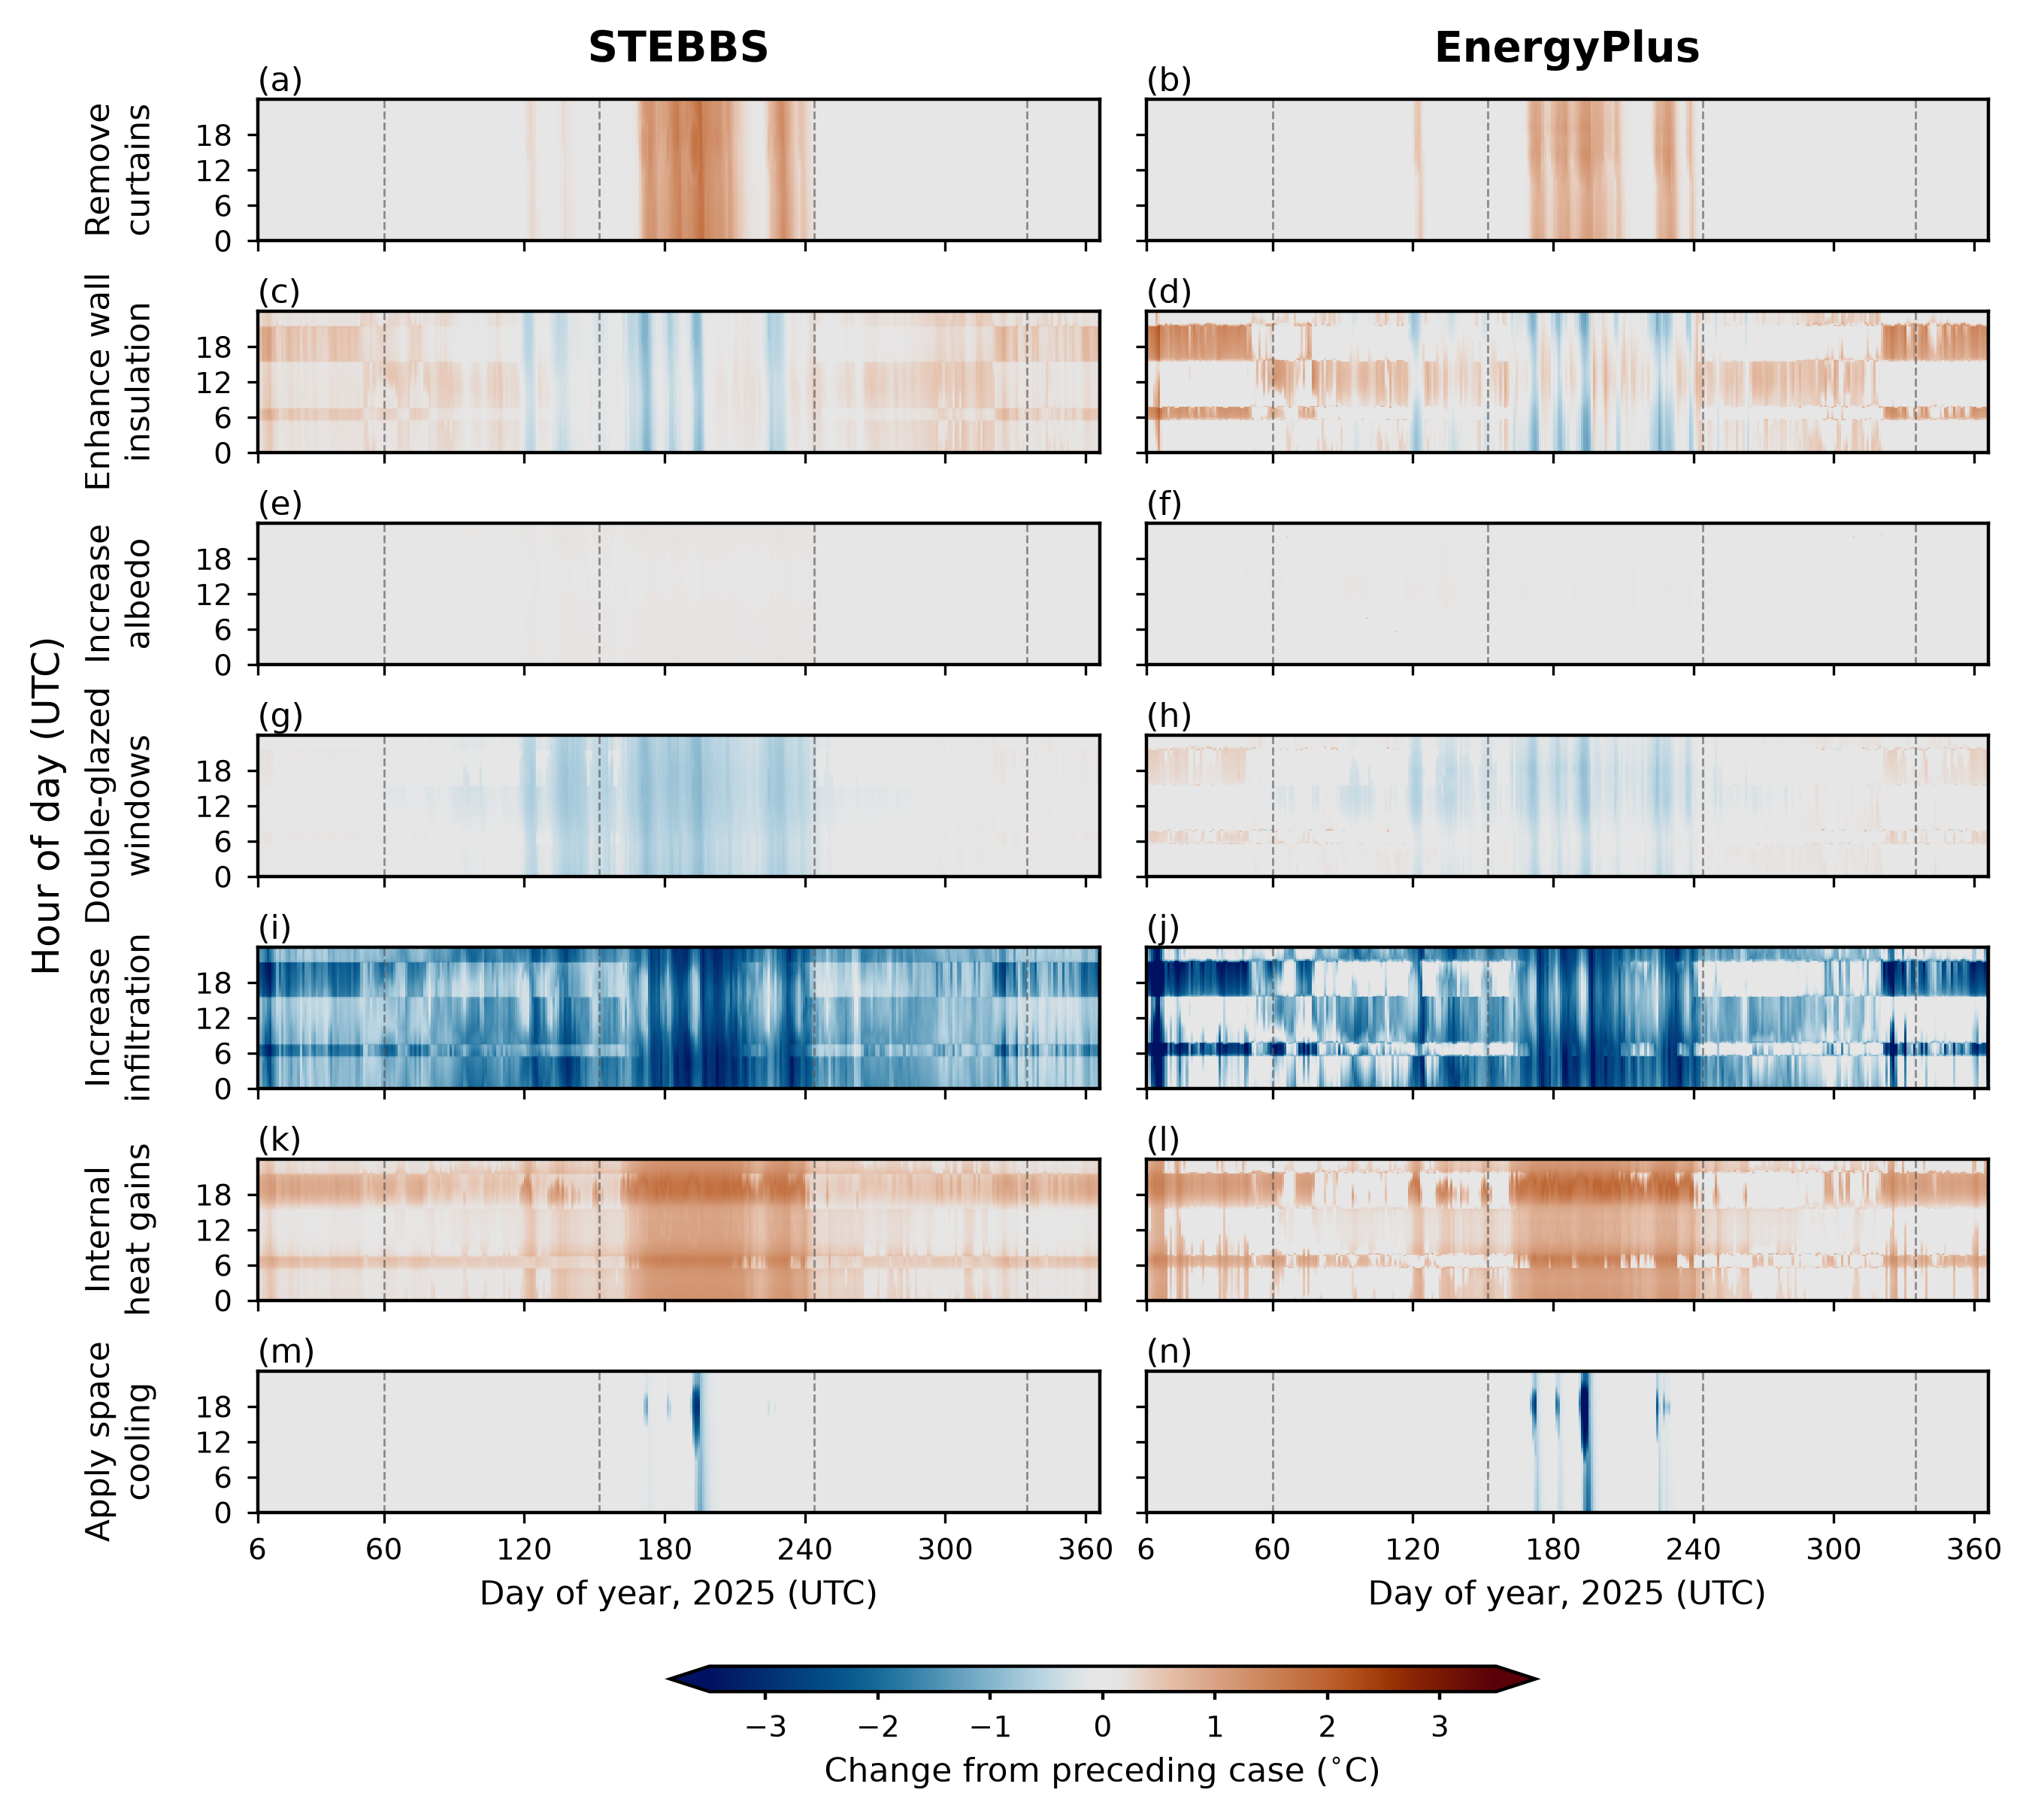

In [15]:
incremental_temperature = pd.DataFrame(
    {
        (model, f"Evaluation_{number}"): (
            annual_temperature[model, f"Evaluation_{number}"]
            - annual_temperature[model, f"Evaluation_{number - 1}"]
        )
        for model in ["STEBBS", "EnergyPlus"]
        for number in range(1, 8)
    },
    index=annual_index,
)
incremental_temperature.columns = pd.MultiIndex.from_tuples(
    incremental_temperature.columns, names=["model", "case"]
)

incremental_rows = []
for model in ["STEBBS", "EnergyPlus"]:
    for number in range(1, 8):
        case = f"Evaluation_{number}"
        change = incremental_temperature[model, case].dropna()
        if change.empty:
            raise ValueError(f"No paired temperatures for {model} {case}")
        incremental_rows.append(
            {
                "model": model,
                "case": case,
                "paired_intervals": len(change),
                "mean_change_C": change.mean(),
                "minimum_C": change.min(),
                "maximum_C": change.max(),
                "outside_plot_scale_percent": 100 * (change.abs() > 3.5).mean(),
            }
        )
incremental_statistics = pd.DataFrame(incremental_rows).set_index(["model", "case"])

measure_labels = [
    "Remove\ncurtains",
    "Enhance wall\ninsulation",
    "Increase\nalbedo",
    "Double-glazed\nwindows",
    "Increase\ninfiltration",
    "Internal\nheat gains",
    "Apply space\ncooling",
]
incremental_cmap = vik_neutral.with_extremes(bad="#777777")
incremental_norm = TwoSlopeNorm(vmin=-3.5, vcenter=0, vmax=3.5)

with plt.rc_context(figure_style):
    figure_15, axes_15 = plt.subplots(
        7, 2,
        figsize=(FIGURE_WIDTH, FIGURE_WIDTH * 0.90),
        dpi=FIGURE_DPI,
        sharex=True,
        sharey=True,
    )
    figure_15.subplots_adjust(
        left=0.125,
        right=0.985,
        bottom=0.16,
        top=0.94,
        hspace=0.50,
        wspace=0.055,
    )
    for row in range(7):
        for column, model in enumerate(["STEBBS", "EnergyPlus"]):
            axis = axes_15[row, column]
            change_matrix = incremental_temperature[
                model, f"Evaluation_{row + 1}"
            ].to_numpy().reshape(len(annual_days), 96).T
            incremental_mesh = axis.pcolormesh(
                day_edges,
                hour_edges,
                change_matrix,
                cmap=incremental_cmap,
                norm=incremental_norm,
                shading="flat",
                rasterized=True,
            )
            for boundary in season_boundaries:
                axis.axvline(
                    boundary,
                    color="0.35",
                    linewidth=0.5,
                    linestyle="--",
                    alpha=0.65,
                )
            axis.set(
                xlim=(day_edges[0], day_edges[-1]),
                ylim=(0, 24),
                yticks=[0, 6, 12, 18],
                xticks=day_ticks,
            )
            axis.tick_params(length=2.5, width=0.6, labelsize=7)
            axis.set_title(
                f"({chr(97 + row * 2 + column)})", loc="left", fontsize=8, pad=2
            )
        axes_15[row, 0].set_ylabel(measure_labels[row], fontsize=8, labelpad=8)
        axes_15[row, 0].yaxis.set_label_coords(-0.115, 0.5)

    for column, model in enumerate(["STEBBS", "EnergyPlus"]):
        position = axes_15[0, column].get_position()
        figure_15.text(
            (position.x0 + position.x1) / 2,
            0.967,
            model,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
        )
        axes_15[-1, column].set_xlabel(
            f"Day of year, {YEAR} (UTC)", fontsize=8, labelpad=3
        )
    figure_15.supylabel("Hour of day (UTC)", x=0.012, y=0.55)
    incremental_colour_axis = figure_15.add_axes([0.33, 0.061, 0.43, 0.014])
    incremental_colourbar = figure_15.colorbar(
        incremental_mesh,
        cax=incremental_colour_axis,
        orientation="horizontal",
        ticks=np.arange(-3, 4),
        extend="both",
    )
    incremental_colourbar.set_label(
        "Change from preceding case ($^{\\circ}$C)", fontsize=8, labelpad=3
    )
    incremental_colourbar.ax.tick_params(labelsize=7, length=2)
    figure_15_path = FIGURE_DIR / "figure_15.png"
    figure_15.savefig(figure_15_path, dpi=FIGURE_DPI, facecolor="white")
    plt.show()